In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import os
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from scipy.stats import pearsonr

from peft import LoraConfig, get_peft_model

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
from epihydra import VocabWrapper, AgePredictor, load_backbone, build_dataloaders, evaluate

In [3]:
data_path = Path('/work/gr-fe/bryan/EpiHydra/data/03_final/GSE55763/methylation.pkl')
model_path = Path('/work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/tiny')
epihydra_path = Path('/work/gr-fe/bryan/EpiHydra/data/03_final/tensorboard/checkpoints/nlayers6_nhead4_emb64_lr1e-04_bs16_mask0.15_heads4_20260826_163621/')

In [4]:
print("Loading data...")
with open(data_path, "rb") as f:
    data = pickle.load(f)

# methylgpt model config
with open(model_path / "args.json", "r") as f:
    pretrain_config = json.load(f)

# ── Build vocab ──────────────────────────────────────────────────
vocab = VocabWrapper(model_path / "vocab.json" , pretrain_config["n_hvg"])

# ── model_args — passed through to precompute_tokens ────────────
model_args = {
    "n_hvg"      : pretrain_config["n_hvg"],
    "mask_ratio" : 0.15,
    "mask_value" : -1,   # -1, defined in VocabWrapper
}

Loading data...


In [5]:
splits = build_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_age    = 'age',
    train_ratio  = 0.7,
    valid_ratio  = 0.15,
    test_ratio   = 0.15,
    batch_size   = 16,
    num_workers  = 0,
    random_state = 42,
    verbose      = True,
)
train_loader = splits["train_loader"]
valid_loader = splits["valid_loader"]
test_loader  = splits["test_loader"]
scaler       = splits["scaler"]

Samples in meta : 2711
Samples in CpG  : 2711
Common samples  : 2711
Samples after NaN drop : 2711

Vocab CpGs : 49,159 | Present : 44,090 (89.7%) | Missing : 5,069
ℹ  Missing CpGs → NaN → padded during tokenisation.

Train : 1897 | Valid : 407 | Test : 407
Age range (train) : 24.5 – 75.0 years
ℹ  Scaler fitted on training ages.
ℹ  CpG variance ranks computed (49,159 probes). Mask modes: uniform=90%, high_var=10%, low_var=0%
✓ Data loaded and ready.



/work/gr-fe/bryan/EpiHydra/epihydra/epihydra.py:125: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(X, axis=0)                  # (n_cpgs,) — NaN where all-NaN probe


In [10]:
backbone  = load_backbone(model_path / "tiny-best_model_epoch10.pt", vocab, pretrain_config)
pad_id    = vocab.vocab["<pad>"]
age_model = AgePredictor(
    backbone,
    embed_dim = pretrain_config["layer_size"],
    pad_id    = pad_id,
    num_heads = 4,
    dropout   = 0.1,
).to(device)

config = LoraConfig(
    r=8,                              
    lora_alpha=16,
    target_modules=["Wqkv", "out_proj","linear1" , "linear2"], 
    lora_dropout=0.1,
)

age_model.backbone = get_peft_model(age_model.backbone, config)

Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/tiny/tiny-best_model_epoch10.pt


In [7]:
print("\nLoading best checkpoint for test evaluation...")
checkpoint = torch.load(epihydra_path / "best_model.pt", map_location=device)
age_model.load_state_dict(checkpoint["model_state"])


Loading best checkpoint for test evaluation...


RuntimeError: Error(s) in loading state_dict for AgePredictor:
	size mismatch for head.query: copying a param with shape torch.Size([1, 1, 64]) from checkpoint, the shape in current model is torch.Size([1, 4, 64]).

In [8]:
# Freeze everything in the backbone
for param in age_model.backbone.parameters():
    param.requires_grad = False

# Make sure the head is trainable
for param in age_model.head.parameters():
    param.requires_grad = True


In [12]:

# Unfreeze backbone LoRA params
for name, param in age_model.backbone.named_parameters():
    param.requires_grad = 'lora' in name.lower()

# Head always trainable
for param in age_model.head.parameters():
    param.requires_grad = True

In [13]:
print(age_model.backbone.print_trainable_parameters())

trainable params: 32,264 || all params: 3,359,562 || trainable%: 0.9604
None


In [15]:
NUM_EPOCHS = 40
LORA_R     = 8
LORA_ALPHA = 16

config = LoraConfig(
    r              = LORA_R,
    lora_alpha     = LORA_ALPHA,
    target_modules = ['Wqkv', 'out_proj', 'linear1', 'linear2'],
    lora_dropout   = 0.1,
)
age_model.backbone = get_peft_model(age_model.backbone, config)
age_model.backbone.print_trainable_parameters()

# Unfreeze backbone LoRA params
for name, param in age_model.backbone.named_parameters():
    param.requires_grad = 'lora' in name.lower()

# Head always trainable
for param in age_model.head.parameters():
    param.requires_grad = True

lora_params = [p for n, p in age_model.backbone.named_parameters() if p.requires_grad]
head_params = list(age_model.head.parameters())

optimizer = torch.optim.AdamW([
    {'params': lora_params, 'lr': 1e-3},
    {'params': head_params, 'lr': 1e-3},
], weight_decay=0.01)

scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-5)
criterion  = nn.MSELoss()
scaler_amp = torch.cuda.amp.GradScaler()

best_mae, best_epoch = float('inf'), 0
diag_done = False

for epoch in range(1, NUM_EPOCHS + 1):
    age_model.train()
    train_losses = []

    for batch_idx, batch in enumerate(train_loader):
        gene_ids, masked_vals, target_vals, ages, ages_norm, ids = batch
        gene_ids    = gene_ids.to(device)
        masked_vals = masked_vals.to(device)
        ages_norm   = ages_norm.to(device).squeeze()

        with torch.cuda.amp.autocast():
            pred = age_model(gene_ids, masked_vals)
            loss = criterion(pred, ages_norm)

        optimizer.zero_grad()
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(optimizer)
        scaler_amp.step(optimizer)
        scaler_amp.update()
        train_losses.append(loss.item())

        # ── Inline diagnostics — first batch of first epoch only ──────────────
        if not diag_done and epoch == 1 and batch_idx == 0:
            print('\n' + '='*55)
            print('  Diagnostics (epoch 1, batch 1)')
            print('='*55)

            # 1. Gradient flow — LoRA
            lora_with  = [(n, p) for n, p in age_model.backbone.named_parameters()
                          if p.requires_grad and p.grad is not None and p.grad.abs().sum() > 0]
            lora_zero  = [(n, p) for n, p in age_model.backbone.named_parameters()
                          if p.requires_grad and (p.grad is None or p.grad.abs().sum() == 0)]
            head_with  = [(n, p) for n, p in age_model.head.named_parameters()
                          if p.requires_grad and p.grad is not None and p.grad.abs().sum() > 0]
            head_zero  = [(n, p) for n, p in age_model.head.named_parameters()
                          if p.requires_grad and (p.grad is None or p.grad.abs().sum() == 0)]

            lora_ok = len(lora_with) > 0
            head_ok = len(head_with) > 0
            print(f'  LoRA grads : {len(lora_with)} flowing, {len(lora_zero)} zero  {"✓" if lora_ok else "✗ FAIL"}')
            print(f'  Head grads : {len(head_with)} flowing, {len(head_zero)} zero  {"✓" if head_ok else "✗ FAIL"}')

            # 2. LoRA weight update check — save weights before next step
            lora_snapshot = {n: p.data.clone() for n, p in age_model.backbone.named_parameters() if p.requires_grad}

            # 3. Masking
            n_mask  = (masked_vals == -1).sum().item()
            n_pad   = (masked_vals == -2).sum().item()
            n_real  = masked_vals.numel() - n_pad
            mask_ok = n_mask > 0 and (target_vals == -1).sum().item() == 0
            print(f'  Masking    : {n_mask:,} masked ({n_mask/n_real*100:.1f}% of real)  {"✓" if mask_ok else "✗ FAIL"}')

            # 4. Beta value range
            real = target_vals[(target_vals != -2) & (target_vals != -1)].float()
            beta_ok = real.min().item() >= -0.1 and real.max().item() <= 1.1
            print(f'  Beta range : {real.min().item():.4f} – {real.max().item():.4f}  {"✓" if beta_ok else "✗ FAIL — values outside [0,1]"}')

            # 5. Prediction variance
            pred_ok = pred.std().item() > 1e-4
            print(f'  Pred std   : {pred.std().item():.4f}  {"✓" if pred_ok else "✗ FAIL — head collapsed"}')
            print(f'  Loss       : {loss.item():.6f}')
            print('='*55 + '\n')
            diag_done = True

    # ── Check LoRA weights actually updated after epoch 1 ────────────────────
    if epoch == 1 and 'lora_snapshot' in dir():
        changed = sum(
            1 for n, p in age_model.backbone.named_parameters()
            if p.requires_grad and not torch.allclose(p.data, lora_snapshot[n])
        )
        print(f'  LoRA weight updates: {changed}/{len(lora_snapshot)} params changed  {"✓" if changed > 0 else "✗ FAIL — weights not updating"}')

    # ── Validate ──────────────────────────────────────────────────────────────
    age_model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for gene_ids, masked_vals, target_vals, ages, ages_norm, ids in valid_loader:
            gene_ids    = gene_ids.to(device)
            target_vals = target_vals.to(device)
            with torch.cuda.amp.autocast():
                pred = age_model(gene_ids, target_vals)
            pred_age = scaler.inverse_transform(
                pred.float().cpu().numpy().reshape(-1, 1)
            ).flatten()
            all_preds.extend(pred_age)
            all_labels.extend(ages.numpy())

    mae  = np.mean(np.abs(np.array(all_preds) - np.array(all_labels)))
    lr   = scheduler.get_last_lr()[0]
    scheduler.step()

    if mae < best_mae:
        best_mae, best_epoch = mae, epoch

    print(f'Epoch {epoch:3d}/{NUM_EPOCHS} | Train loss: {np.mean(train_losses):.4f} | Valid MAE: {mae:.2f} yrs | Best: {best_mae:.2f} yrs (ep {best_epoch}) | LR: {lr:.2e}')


trainable params: 32,264 || all params: 3,359,562 || trainable%: 0.9604


/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/einops/_torch_specific.py:115: ImportWarning: allow_ops_in_compiled_graph failed to import torch: ensure pytorch >=2.0
  warnings.warn(



  Diagnostics (epoch 1, batch 1)
  LoRA grads : 26 flowing, 26 zero  ✓
  Head grads : 11 flowing, 0 zero  ✓
  Masking    : 49,351 masked (7.0% of real)  ✓
  Beta range : -0.8138 – 1.4537  ✗ FAIL — values outside [0,1]
  Pred std   : 0.0159  ✓
  Loss       : 0.034888



KeyboardInterrupt: 

In [16]:
            lora_with  = [(n, p) for n, p in age_model.backbone.named_parameters()
                          if p.requires_grad and p.grad is not None and p.grad.abs().sum() > 0]
            lora_zero  = [(n, p) for n, p in age_model.backbone.named_parameters()
                          if p.requires_grad and (p.grad is None or p.grad.abs().sum() == 0)]
            head_with  = [(n, p) for n, p in age_model.head.named_parameters()
                          if p.requires_grad and p.grad is not None and p.grad.abs().sum() > 0]
            head_zero  = [(n, p) for n, p in age_model.head.named_parameters()
                          if p.requires_grad and (p.grad is None or p.grad.abs().sum() == 0)]

In [20]:
head_zero

[]

In [18]:
lora_zero

[]

In [11]:
test_mae, test_preds, test_labels = evaluate(age_model, test_loader, scaler, device)

In [12]:
test_r2   = r2_score(test_labels, test_preds)
test_r, _ = pearsonr(test_labels, test_preds)

print(f"\n{'─'*40}")
print(f"  Test MAE      : {test_mae:.2f} years")
print(f"  Test R²       : {test_r2:.3f}")
print(f"  Test Pearson r: {test_r:.3f}")
print(f"{'─'*40}\n")


────────────────────────────────────────
  Test MAE      : 10.19 years
  Test R²       : 0.024
  Test Pearson r: 0.485
────────────────────────────────────────



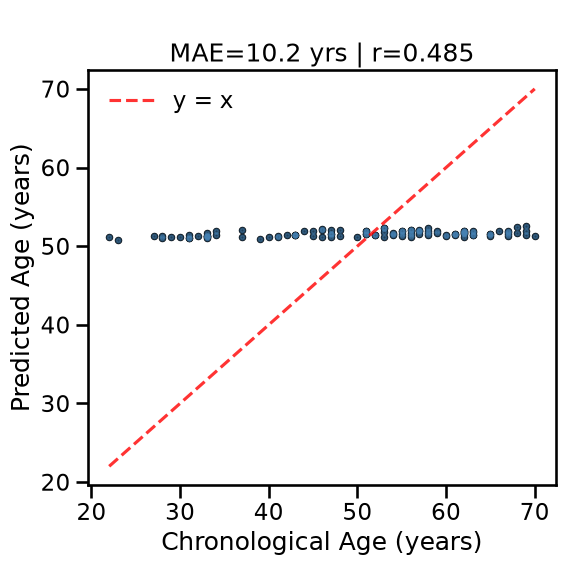

In [13]:
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test_labels, test_preds, s=15, c="black",    alpha=1.0,  zorder=1)
ax.scatter(test_labels, test_preds, s=10, alpha=0.5, c="steelblue", zorder=2)
lims = [min(test_labels.min(), test_preds.min()),
        max(test_labels.max(), test_preds.max())]
ax.plot(lims, lims, "r--", alpha=0.8, label="y = x")
ax.set_xlabel("Chronological Age (years)")
ax.set_ylabel("Predicted Age (years)")
ax.set_title(f"\nMAE={test_mae:.1f} yrs | r={test_r:.3f}")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()